In [2]:
import numpy as np
import matplotlib.pyplot as plt

def error_channel(c: np.array, p: float, n: int = 1) -> list:
    '''
    c --- сообщение
    p --- вероятность ошибки
    n --- кол-во повторов
    '''
    set_of_c = []
    for _ in range(n):
        error_vec = np.random.choice(2, len(c), p=[1. - p, p])
        error_c = (c + error_vec) % 2
        set_of_c.append(np.array(error_c))

    return set_of_c

def dot_for_codes(a: np.array, b: np.array) -> np.array:
    return np.array(a @ b % 2)

def bitflipping_decoding(r, H, equation_matrix, bit_in_sindrom, max_deep, deep=0):
    if deep >= max_deep:
        return r

    S = dot_for_codes(H, r.T)

    if not np.any(S):
        return r
    
    strange_bits = {}
    for i in range(len(S)):
        if S[i] == 1:
            for bit in equation_matrix[i]:
                strange_bits[bit] = strange_bits.get(bit, 0) + 1
    strangest_bit = min(strange_bits.items(), key=lambda x: bit_in_sindrom[x[0]] - x[1])[0]
    r[strangest_bit] = (r[strangest_bit] + 1) % 2
    return bitflipping_decoding(r, H, equation_matrix, bit_in_sindrom, max_deep, deep=deep + 1)

def bitflipping_decoding_for_many(r_messages: np.array, H: np.array) -> list:
    # Нужно создать систему уравнений
    equation_matrix = []
    bit_in_sindrom = [0 for i in range(len(r_messages))]
    rows, cols = H.shape

    for i in range(rows):
        row = []
        for j in range(cols):
            if H[i, j] == 1:
                bit_in_sindrom[j] += 1
                row.append(j)
        equation_matrix.append(row)

    for i in range(len(r_messages)):
        r_messages[i] = bitflipping_decoding(r_messages[i].copy(), H, equation_matrix, bit_in_sindrom, max_deep=100)

    return r_messages

rs = {}

c = np.array(list(map(int, open("../data/message.txt", "r").read().split(","))))

ps = np.linspace(0, 0.1, 50)

for p in ps:
    rs[p] = error_channel(c, p, n=1000)

# мои примеры
H = np.loadtxt('../data/matrix.txt', delimiter=',', dtype=int)

decode_p = []
flip_p = []

for p in ps:
    r = rs[p]
    corrected_rs = bitflipping_decoding_for_many(r, H)
    count_correct = 0
    for corrected_r in corrected_rs:
        count_correct += np.array_equal(corrected_r, c)
    flip_p.append(p)
    decode_p.append((len(r) - count_correct) / len(r))

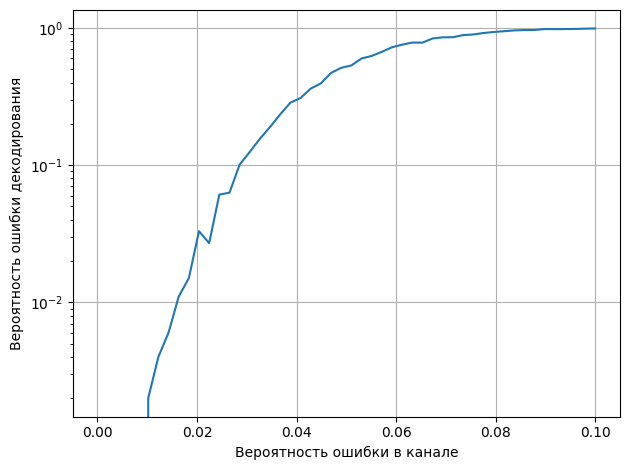

In [3]:
plt.plot(flip_p, decode_p)
plt.ylabel('Вероятность ошибки декодирования')
plt.xlabel('Вероятность ошибки в канале')
plt.yscale('log')
plt.grid()
plt.tight_layout()
plt.savefig('../data/p_log.pdf')
plt.show()

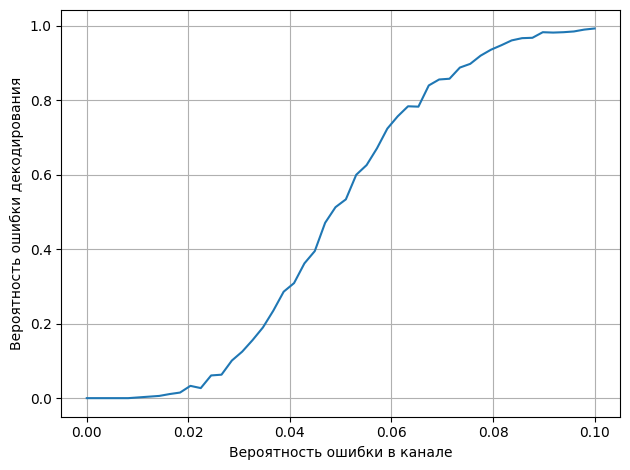

In [4]:
plt.plot(flip_p, decode_p)
plt.ylabel('Вероятность ошибки декодирования')
plt.xlabel('Вероятность ошибки в канале')
plt.grid()
plt.tight_layout()
plt.savefig('../data/p_linear.pdf')
plt.show()